## Notebook and DF prep

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import dotenv_values
from sqlalchemy import create_engine
import textwrap
from matplotlib.patches import Rectangle


config = dotenv_values('../.env')
engine = create_engine(
    f"postgresql+psycopg2://{config['DB_USER']}:{config['DB_PASSWORD']}"
    f"@{config['DB_HOST']}:{config['DB_PORT']}/{config['DB_NAME']}"
)

shades = pd.read_sql('select a_star, b_star, l_star, monk_tone, hex_final from dev.fct_shades', engine)
shades = shades.sort_values('l_star', ascending=False)

out_dir = '../03_tableau/images'
os.makedirs(out_dir, exist_ok=True)
bg = '#6e6e6e'

## Color map: all shades

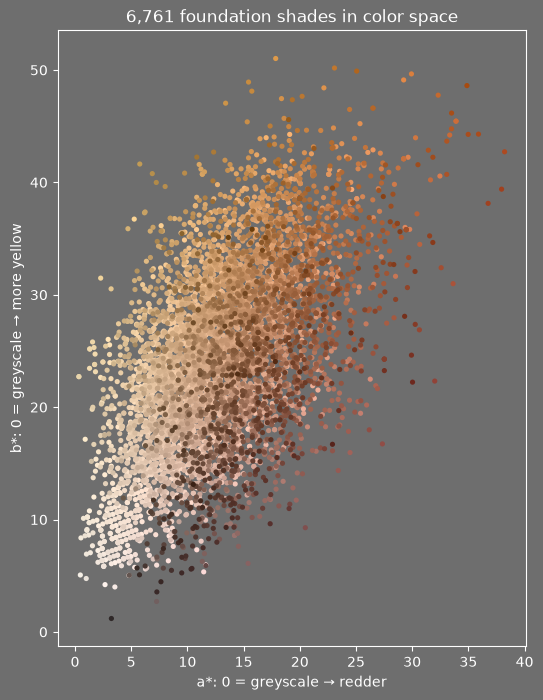

In [10]:
fig, ax = plt.subplots(figsize=(10, 8), facecolor=bg)
ax.set_facecolor(bg)
ax.scatter(shades['a_star'], shades['b_star'], c=shades['hex_final'], s=14, linewidths=0)
ax.set_aspect('equal')
ax.set_xlabel('a*: 0 = greyscale → redder', color='white')
ax.set_ylabel('b*: 0 = greyscale → more yellow', color='white')
ax.set_title(f'{len(shades):,} foundation shades in color space', color='white')
ax.tick_params(colors='white')
for spine in ax.spines.values():
    spine.set_color('white')
plt.savefig(f'{out_dir}/color_map_all.png', dpi=200, bbox_inches='tight', facecolor=bg)
plt.show()

## Color map: one panel per Monk tone

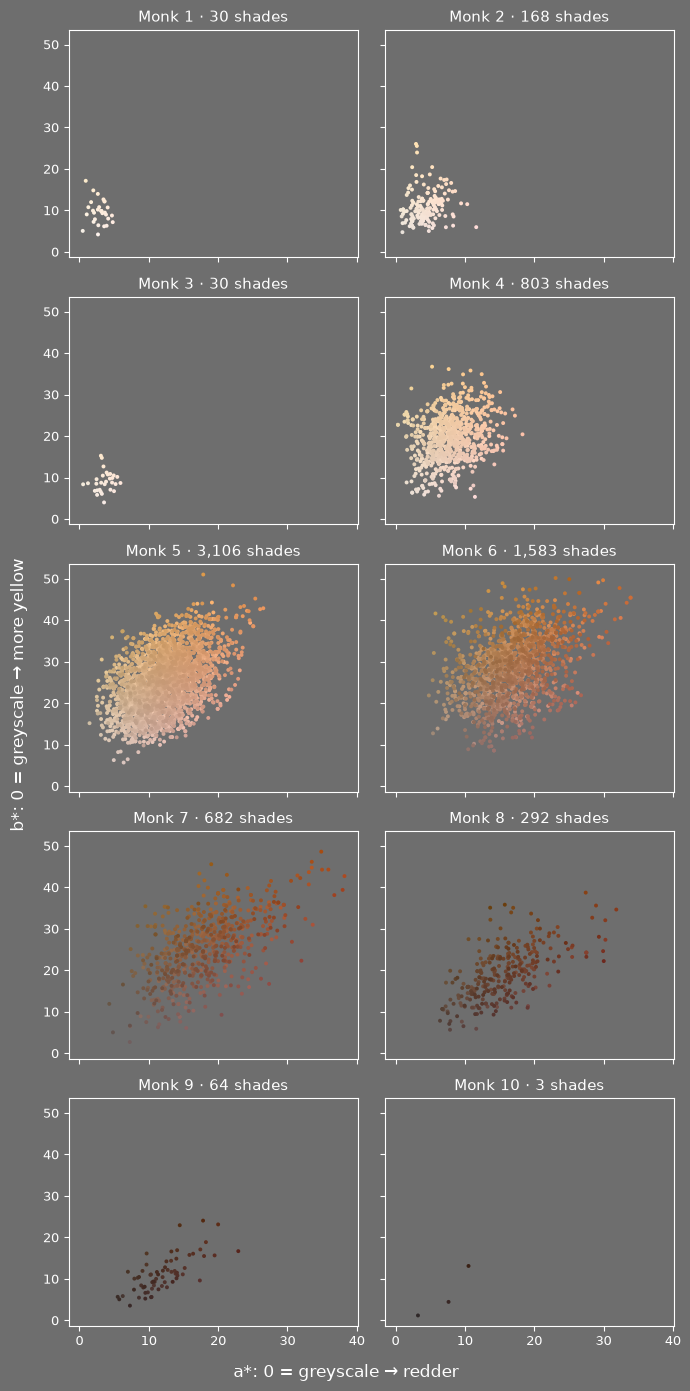

In [3]:
fig, axes = plt.subplots(5, 2, figsize=(7, 14), sharex=True, sharey=True, facecolor=bg)
for tone, ax in zip(range(1, 11), axes.flat):
    sub = shades[shades['monk_tone'] == tone]
    ax.set_facecolor(bg)
    ax.scatter(sub['a_star'], sub['b_star'], c=sub['hex_final'], s=8, linewidths=0)
    ax.set_title(f'Monk {tone} · {len(sub):,} shades', color='white', fontsize=11)
    ax.tick_params(colors='white', labelsize=9)
    for spine in ax.spines.values():
        spine.set_color('white')
fig.supxlabel('a*: 0 = greyscale → redder', color='white')
fig.supylabel('b*: 0 = greyscale → more yellow', color='white')
fig.tight_layout()
plt.savefig(f'{out_dir}/color_map_by_monk.png', dpi=200, bbox_inches='tight', facecolor=bg)
plt.show()

## Twin shades

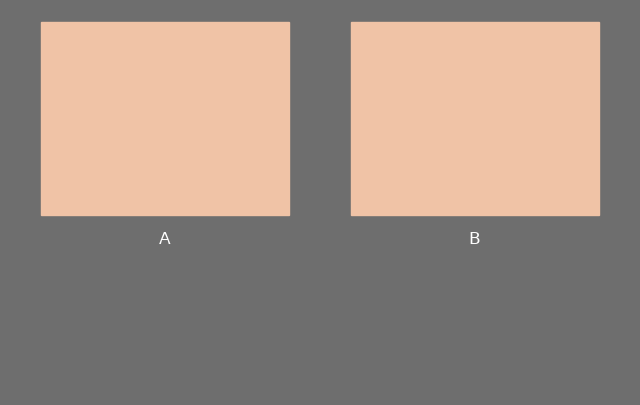

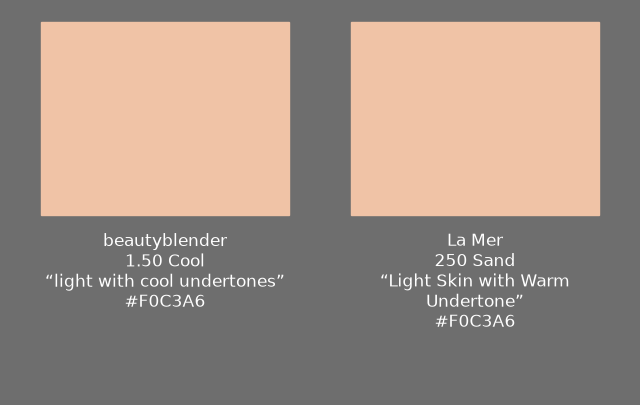

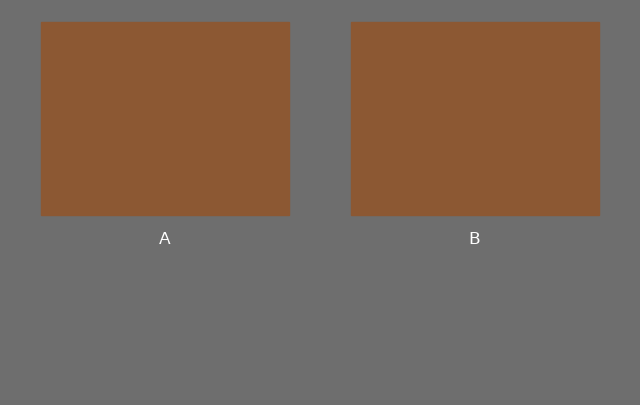

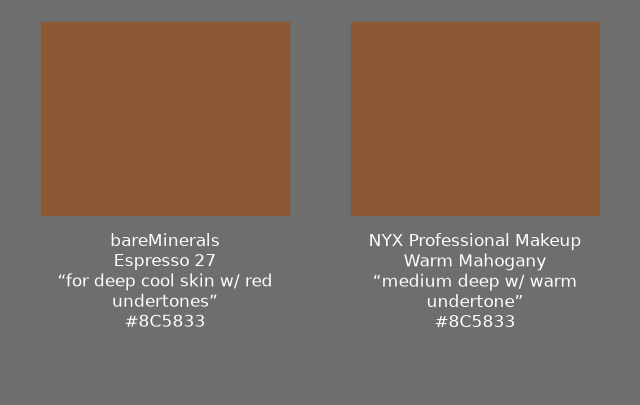

In [2]:

pairs = {
    'light': [
        {'brand': 'beautyblender', 'shade': '1.50 Cool',
         'description': 'light with cool undertones', 'hex': '#F0C3A6'},
        {'brand': 'La Mer', 'shade': '250 Sand',
         'description': 'Light Skin with Warm Undertone', 'hex': '#F0C3A6'},
    ],
    'deep': [
        {'brand': 'bareMinerals', 'shade': 'Espresso 27',
         'description': 'for deep cool skin w/ red undertones', 'hex': '#8C5833'},
        {'brand': 'NYX Professional Makeup', 'shade': 'Warm Mahogany',
         'description': 'medium deep w/ warm undertone', 'hex': '#8C5833'},
    ],
}

def draw_pair(pair, labelled, filename):
    fig, ax = plt.subplots(figsize=(8, 5), facecolor=bg)
    ax.set_facecolor(bg)
    ax.set_xlim(0, 2)
    ax.set_ylim(-0.4, 1.2)
    ax.axis('off')
    for i, s in enumerate(pair):
        x = 0.1 + i
        ax.add_patch(Rectangle((x, 0.35), 0.8, 0.8, color=s['hex']))
        if labelled:
            text = (f"{s['brand']}\n{s['shade']}\n"
                    + textwrap.fill(f"\u201c{s['description']}\u201d", 28)
                    + f"\n{s['hex']}")
        else:
            text = 'A' if i == 0 else 'B'
        ax.text(x + 0.4, 0.28, text, color='white', ha='center', va='top', fontsize=12)
    plt.savefig(f'{out_dir}/{filename}', dpi=200, bbox_inches='tight', facecolor=bg)
    plt.show()

for name, pair in pairs.items():
    draw_pair(pair, labelled=False, filename=f'twins_{name}_vote.png')
    draw_pair(pair, labelled=True, filename=f'twins_{name}_reveal.png')

## Monk dots

In [2]:
monk = pd.read_sql('select * from dev.monk_scale_lab', engine)
monk.head(10)

,monk_tone,hex,L_star
0,1,#f6ede4,94.211092
1,2,#f3e7db,92.274769
2,3,#f7ead0,93.091096
3,4,#eadaba,87.573317
4,5,#d7bd96,77.902219
5,6,#a07e56,55.142877
6,7,#825c43,42.470001
7,8,#604134,30.678265
8,9,#3a312a,21.069480
9,10,#292420,14.610244


In [3]:
monk.columns = monk.columns.str.lower()
print(list(monk.columns))

['monk_tone', 'hex', 'l_star']


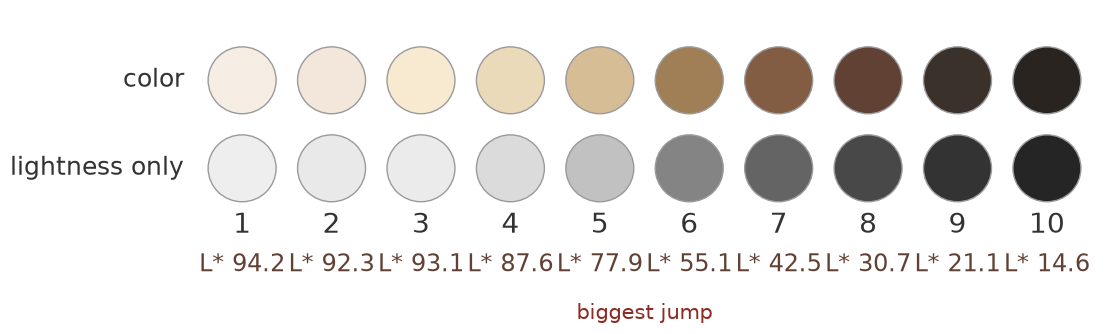

In [6]:
def lstar_to_grey_hex(l_star):
    y = ((l_star + 16) / 116) ** 3 if l_star > 8 else l_star / 903.3
    v = 12.92 * y if y <= 0.0031308 else 1.055 * y ** (1 / 2.4) - 0.055
    g = round(max(0, min(1, v)) * 255)
    return f'#{g:02X}{g:02X}{g:02X}'

monk = monk.sort_values('monk_tone')
monk['grey_hex'] = monk['l_star'].apply(lstar_to_grey_hex)

bg_dots = 'white'
fig, ax = plt.subplots(figsize=(12, 3.6), facecolor=bg_dots)   # CHANGED: 3.2 -> 3.6, a bit taller
ax.set_facecolor(bg_dots)
ax.set_xlim(0.3, 10.7)
ax.set_ylim(-0.95, 2.2)                                        # CHANGED: -0.5 -> -0.95, room for the new line
ax.axis('off')
for _, row in monk.iterrows():
    x = row['monk_tone']
    ax.add_patch(plt.Circle((x, 1.4), 0.38, facecolor=row['hex'], edgecolor='#9a9a9a', linewidth=1))
    ax.add_patch(plt.Circle((x, 0.4), 0.38, facecolor=row['grey_hex'], edgecolor='#9a9a9a', linewidth=1))
    ax.text(x, -0.25, str(int(x)), color='#333333', ha='center', va='center', fontsize=20)          # was 12
    ax.text(x, -0.7, f"L* {row['l_star']:.1f}", color='#604134', ha='center', va='center', fontsize=17)   # was 10, and -0.65 -> -0.7
ax.text(0.35, 1.4, 'color', color='#333333', ha='right', va='center', fontsize=18)                   # was 11
ax.text(0.35, 0.4, 'lightness only', color='#333333', ha='right', va='center', fontsize=18)          # was 11
ax.annotate('', xy=(6, -1.0), xytext=(5, -1.0),
            arrowprops=dict(arrowstyle='<->', color='#8E2B24', linewidth=2))
ax.text(5.5, -1.25, 'biggest jump', color='#8E2B24', ha='center', va='center', fontsize=15)
plt.savefig(f'{out_dir}/monk_dots.png', dpi=200, bbox_inches='tight', facecolor=bg_dots)
plt.show()


In [5]:
monk[['monk_tone', 'l_star']]

,monk_tone,l_star
0,1,94.211092
1,2,92.274769
2,3,93.091096
3,4,87.573317
4,5,77.902219
5,6,55.142877
6,7,42.470001
7,8,30.678265
8,9,21.069480
9,10,14.610244
